Sensor types: temperature, humidity, pressure
Please select a valid sensor type.
Please enter a valid integer.
Please enter a positive number.
Please enter a positive number.
Please enter a positive number.
Please enter a positive number.
Maximum must be greater than minimum.
Maximum must be greater than minimum.
Threshold must be between minimum and maximum.
Sensor selection: temperature
Number of readings: 10
Minimal sensor value: 10.0
Maximum sensor value: 50.0
Alert threshold: 17.7
[11.57411483 29.30455307 24.97659815 47.70280329 16.11300461 44.21582937
 17.29014157 30.03804708 29.50682436 10.69635469]
Counts of duplicates: 0


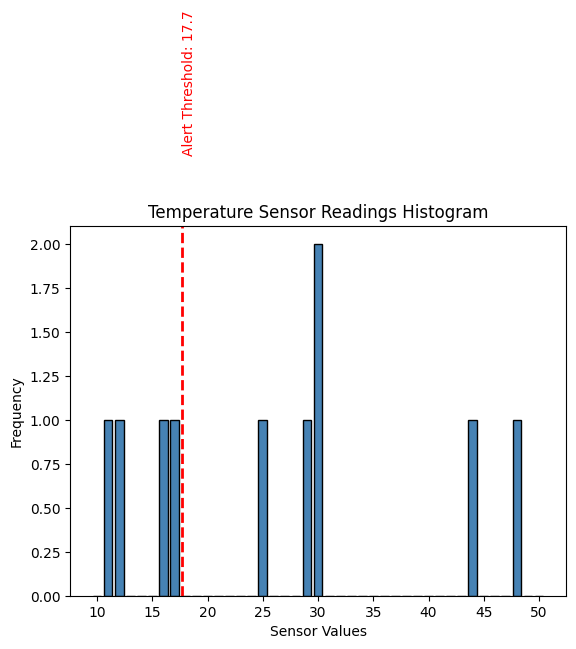

In [ ]:
import numpy as np
import matplotlib.pyplot as plt 


#__1__USER INPUT__ ---------------------------------------------
def get_user_input():
    """ Per functie uitgelegd:
    1 sensor type: De while loop vraagt aan de gebruiker wat voor sensor type hij wilt gebruiken.
    De while loop controleert vervolgens of de input ook in de lijst staat. Anders geeft hij error en vraagt hij opnieuw.

    2 number of readings: Vraagt de hoeveelheid readings die de gebruiker wilt hebben.
    De gebruiker checkt of de input een integer is en of het positief is. Anders komt hier een passende error voor.

    3 minimum: Vraagt de minimale waarde die de sensor als reading kan geven.
    De except checkt of er een float wordt gegeven door de gebruiker. Anders wordt er een error gegeven.

    4 maximum: Vraagt de maximale waarde die de sensor als reading kan geven.
    De except checkt of er een float wordt gegeven door de gebruiker. Anders wordt er een error gegeven. 
    Ook wordt er gechecked of de maximale opgegeven waarde wel hoger is dan de minimale. Anders komt er ook een error.

    5 alert threshold: Vraagt de alert threshold die de sensor als reading kan geven. 
    De except checkt of er een float wordt gegeven door de gebruiker. Anders wordt er een error gegeven. 
    Ook wordt er gechecked of de alert threshold tussen de minimale en maximale waarde ligt. Anders komt er ook een error.                  
    
    Returns:
    
    """
    print("Sensor types: temperature, humidity, pressure")
    #sensor type
    while True:
        sensor_selection = input("Select one of the sensor types: ")
        if sensor_selection in ["temperature", "humidity", "pressure"]:
            print("Sensor selection:", sensor_selection)
            break
        print("Please select a valid sensor type.")

    # Number of readings
    while True:
        try:
            num_of_readings = int(input("Select the number of readings: "))
            if num_of_readings >= 0:
                print("Number of readings:", num_of_readings)
                break
            print("Please enter a positive number.")
        except ValueError:
            print("Please enter a valid integer.")

    # Minimum
    while True:
        try:
            min_sensor_value = float(input("Select the minimum value for the sensor: "))
            print("Minimum sensor value:", min_sensor_value)
            break
        
        except ValueError:
            print("Please enter a valid number.")

    # Maximum
    while True:
        try:
            max_sensor_value = float(input("Select the maximum value for the sensor: "))
            if max_sensor_value > min_sensor_value:
                print("Maximum sensor value:", max_sensor_value)    
                break
            print("Maximum must be greater than minimum.")
        except ValueError:
            print("Please enter a valid number.")

    # alert threshold
    while True:
        try:
            alert_threshold = float(input("Select the alert threshold for the sensor: "))
            if min_sensor_value <= alert_threshold <= max_sensor_value:
                break
            print("Threshold must be between minimum and maximum.")
        except ValueError:
            print("Please enter a valid number.")

    return (sensor_selection, num_of_readings, min_sensor_value, max_sensor_value, alert_threshold)


sensor_selection, num_of_readings, min_sensor_value, max_sensor_value, alert_threshold = get_user_input()

print("Sensor selection:", sensor_selection)
print("Number of readings:", num_of_readings)
print("Minimal sensor value:", min_sensor_value)
print("Maximum sensor value:", max_sensor_value)
print("Alert threshold:", alert_threshold)


#__2__GENERATE SENSOR VALUES__ ---------------------------------------------
def generate_readings(num_of_readings, min_sensor_value, max_sensor_value):
    return np.random.uniform(min_sensor_value, max_sensor_value, num_of_readings)
sensor_values = generate_readings(num_of_readings, min_sensor_value, max_sensor_value)
print(sensor_values)


#__3__ANALYSING WITH NUMPY__ -----------------------------------------------

def calculate_statistics(sensor_values):
    num_readings = len(sensor_values)
    max_value = np.max(sensor_values)
    min_value = np.min(sensor_values)
    mean_value = np.mean(sensor_values)
    standard_deviation = np.std(sensor_values)
    return num_readings, max_value, min_value, mean_value, standard_deviation

calculate_statistics(sensor_values)

def find_outliers(sensor_values, alert_threshold):
    num_above_alert_threshold = np.sum(sensor_values > alert_threshold)
    duplicates = np.sum(np.diff(np.sort(sensor_values)) == 0)
    print("Counts of duplicates:", duplicates)
    return num_above_alert_threshold, duplicates

find_outliers(sensor_values, alert_threshold)

#__4__VISUALIZATION__ -----------------------------------------------------

plt.hist(sensor_values, bins=np.arange(min_sensor_value - 0.5, max_sensor_value + 1.5, 1), rwidth=0.8, color='steelblue', edgecolor='black')
plt.axvline(alert_threshold, color='red', linestyle='dashed', linewidth=2)
plt.title(f"{sensor_selection.capitalize()} Sensor Readings Histogram")
plt.xlabel("Sensor Values")
plt.ylabel("Frequency")
plt.text(alert_threshold, plt.ylim()[1]*1.2, f'Alert Threshold: {alert_threshold}', color='red', rotation=90)
plt.show()
plt.grid()  
plt.line(np.arange(min_sensor_value, max_sensor_value + 1, 1), np.zeros_like(np.arange(min_sensor_value, max_sensor_value + 1, 1)), color='black', linewidth=0.5)



